In [ ]:
!pip install surprise

In [ ]:
from google.colab import drive
drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


LIBRERIE PANDAS


In [ ]:
import numpy as np
import pandas as pd
from pandas import plotting
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('fivethirtyeight')
import os
import plotly.graph_objects as go
from sklearn.cluster import KMeans
import surprise
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split as sk_train_test_split
from sklearn.neighbors import NearestNeighbors, KNeighborsRegressor
from surprise import accuracy, Dataset, KNNBasic, Reader
from surprise.model_selection import cross_validate, train_test_split, GridSearchCV

# **1.  ANALISI DEI DATI**

In [ ]:
import warnings
warnings.filterwarnings('ignore')

IMPORTO IL DATASET

In [ ]:
dfc = pd.read_csv('/content/drive/MyDrive/metodi/df_modcloth_marketing_bias.csv', sep = ',', encoding = 'utf-8')

print(dfc.shape)

dfc.head()

(99893, 12)


,item_id,user_id,rating,timestamp,size,fit,user_attr,model_attr,category,brand,year,split
0,7443,Alex,4,2010-01-21 08:00:00+00:00,NaN,NaN,Small,Small,Dresses,NaN,2012,0
1,7443,carolyn.agan,3,2010-01-27 08:00:00+00:00,NaN,NaN,NaN,Small,Dresses,NaN,2012,0
2,7443,Robyn,4,2010-01-29 08:00:00+00:00,NaN,NaN,Small,Small,Dresses,NaN,2012,0
3,7443,De,4,2010-02-13 08:00:00+00:00,NaN,NaN,NaN,Small,Dresses,NaN,2012,0
4,7443,tasha,4,2010-02-18 08:00:00+00:00,NaN,NaN,Small,Small,Dresses,NaN,2012,0


TOLGO I VALORI NULLI

> Blocco con rientro



In [ ]:
dfc.dropna().head()

,item_id,user_id,rating,timestamp,size,fit,user_attr,model_attr,category,brand,year,split
328,21296,Nikki,5,2011-02-16 08:00:00+00:00,3.0,Just right,Small,Small,Bottoms,ModCloth,2013,0
329,21296,ellen,5,2011-02-16 08:00:00+00:00,1.0,Just right,Large,Small,Bottoms,ModCloth,2013,0
340,21296,Sarita,5,2011-02-22 08:00:00+00:00,2.0,Just right,Small,Small,Bottoms,ModCloth,2013,0
351,21296,kacikorn,4,2011-03-01 08:00:00+00:00,1.0,Just right,Small,Small,Bottoms,ModCloth,2013,0
361,21296,lesleydawn88,4,2011-03-06 08:00:00+00:00,1.0,Just right,Small,Small,Bottoms,ModCloth,2013,0


In [ ]:
dfc.describe()

,item_id,rating,size,year,split
count,99893.000000,99893.000000,78133.000000,99893.000000,99893.000000
mean,83944.091208,4.209594,3.217322,2015.476450,0.358564
std,43558.135979,1.080633,1.885934,1.970262,0.720993
min,6454.000000,1.000000,0.000000,2010.000000,0.000000
25%,48629.000000,4.000000,2.000000,2014.000000,0.000000
50%,77878.000000,5.000000,3.000000,2016.000000,0.000000
75%,120126.000000,5.000000,4.000000,2017.000000,0.000000
max,155950.000000,5.000000,8.000000,2019.000000,2.000000


TENGO SOLO LE COLONNE CHE MI SERVONO              

In [ ]:
df = dfc[['item_id','user_id', 'rating','category']]
print(df.shape)
print(df.dtypes)
df.head()

(99893, 4)
item_id      int64
user_id     object
rating       int64
category    object
dtype: object


,item_id,user_id,rating,category
0,7443,Alex,4,Dresses
1,7443,carolyn.agan,3,Dresses
2,7443,Robyn,4,Dresses
3,7443,De,4,Dresses
4,7443,tasha,4,Dresses


CONTROLLO SE CI SONO VALORI NULLI

In [ ]:
df.isnull().sum()
#ELIMINO I VALORI NULLI
df = df.dropna()
df

,item_id,user_id,rating,category
0,7443,Alex,4,Dresses
1,7443,carolyn.agan,3,Dresses
2,7443,Robyn,4,Dresses
3,7443,De,4,Dresses
4,7443,tasha,4,Dresses
...,...,...,...,...
99888,154797,BernMarie,5,Dresses
99889,77949,Sam,4,Bottoms
99890,67194,Janice,5,Dresses
99891,71607,amy,3,Outerwear


In [ ]:
n_ratings = len(df)
n_categories = len(df['category'].unique())
n_users = len(df['user_id'].unique())

ANALIZZO LA TENDEZZA CENTRALE DEI RATING [MEDIA-STD-MEDIANA]

In [ ]:
print(f"Number of ratings: {n_ratings}")
print(f"Number of unique categories : {n_categories}")
print(f"Number of unique users: {n_users}")
print(f"Average ratings per user: {round(n_ratings/n_users, 2)}")
print(f"Average ratings per categories: {round(n_ratings/n_categories, 2)}")

Number of ratings: 99892
Number of unique categories : 4
Number of unique users: 44783
Average ratings per user: 2.23
Average ratings per categories: 24973.0


In [ ]:
df['rating'].describe()

count    99892.000000
mean         4.209606
std          1.080632
min          1.000000
25%          4.000000
50%          5.000000
75%          5.000000
max          5.000000
Name: rating, dtype: float64

In [ ]:
#varianza rating
print('Varianza:', df['rating'].var())
#deviazione standard rating
print('Deviazione standard:', df['rating'].std())
#Devianza assoluta mediana
print('Devianza assoluta mediana:', (df['rating'] - df['rating'].mean()).abs().mean())

Varianza: 1.1677654816015504
Deviazione standard: 1.0806319824998474
Devianza assoluta mediana: 0.8635366062403818


Text(0, 0.5, 'Conteggio')

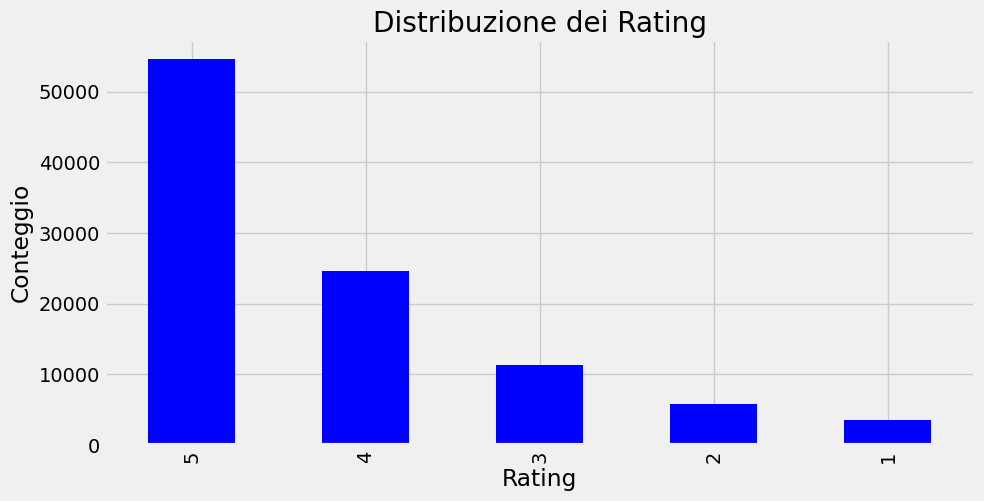

In [ ]:
plt.figure(
    figsize=(10, 5),
    dpi=100)
df['rating'].value_counts().plot(
    kind='bar',
    color='blue',)

plt.title('Distribuzione dei Rating')
plt.xlabel('Rating')
plt.ylabel('Conteggio')

In [ ]:
#TRACCIO IL NUMERO TOTALE DI VALUTAZIONI PER CATEGORIA
df.groupby('category')['rating'].count().sort_values(ascending=False).head()

category
Tops         34977
Dresses      34160
Bottoms      23624
Outerwear     7131
Name: rating, dtype: int64

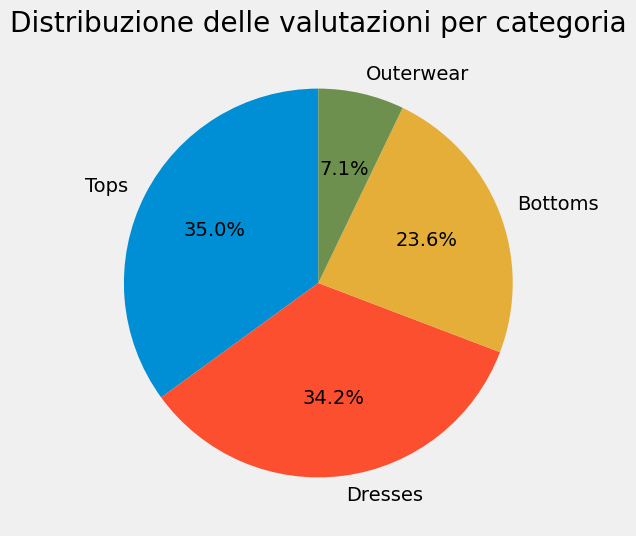

In [ ]:
# Dati delle categorie e relativi valori
categories = ['Tops', 'Dresses', 'Bottoms', 'Outerwear']
values = [34977, 34160, 23624, 7131]

# Crea il grafico a torta
plt.figure(figsize=(8, 6))
plt.pie(values, labels=categories, autopct='%1.1f%%', startangle=90)

plt.title("Distribuzione delle valutazioni per categoria")

# Mostra il grafico
plt.show()

In [ ]:
# Analisi variabili qualitative:
category_rating = df.groupby(['category', 'rating']).rating.count()
category_rating

category   rating
Bottoms    1           942
           2          1378
           3          2705
           4          5935
           5         12664
Dresses    1          1154
           2          1980
           3          3694
           4          8340
           5         18992
Outerwear  1           238
           2           413
           3           822
           4          1746
           5          3912
Tops       1          1189
           2          2080
           3          4138
           4          8570
           5         19000
Name: rating, dtype: int64

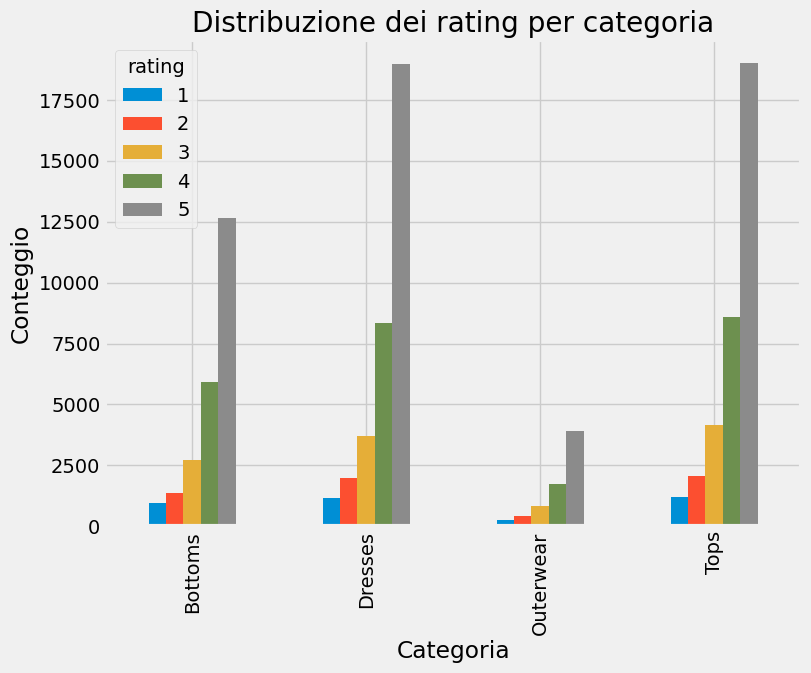

In [ ]:
# Calcola il conteggio dei rating per ogni categoria
category_rating = df.groupby(['category', 'rating']).rating.count()

# Crea un oggetto figura e un'assegnazione degli assi
fig, ax = plt.subplots(figsize=(8, 6))

# Utilizza il metodo bar di matplotlib per creare il grafico a barre
category_rating.unstack().plot(kind='bar', ax=ax)

# Aggiungi titolo e etichette degli assi
ax.set_title('Distribuzione dei rating per categoria')
ax.set_xlabel('Categoria')
ax.set_ylabel('Conteggio')

# Mostra il grafico
plt.show()

FREQUENZA DELLE VALUTAZIONI PER OGNI UTENTE

In [ ]:
user_freq = df[['user_id', 'category']].groupby('user_id').count().reset_index().sort_values(by= 'category', ascending = False)
user_freq.columns = ['user_id', 'n_ratings']
user_freq.head(10)

,user_id,n_ratings
5756,Sarah,250
411,Amanda,204
22660,jennifer,198
3735,Laura,197
2907,Jennifer,191
3333,Katie,188
38602,sarah,187
5353,Rachel,184
2949,Jessica,184
4482,Megan,177


In [ ]:
#DIMENSIONI
users_id = df[('user_id')].unique()
print(users_id.shape)
items_id = df[('item_id')].unique()
print(items_id.shape)

(44783,)
(1020,)


In [ ]:
df.groupby(['user_id', 'item_id']).count()['rating'].describe()

count    99892.0
mean         1.0
std          0.0
min          1.0
25%          1.0
50%          1.0
75%          1.0
max          1.0
Name: rating, dtype: float64

In [ ]:
# CERCO LE CATEGORIE CON RATING PIU' ALTI E PIU' BASSI
mean_rating = df.groupby('category')[['rating']].mean()
print(mean_rating)

             rating
category           
Bottoms    4.185278
Dresses    4.230562
Outerwear  4.217361
Tops       4.203991


In [ ]:
#RATING PER USER_ID
df.groupby('user_id')['rating'].count().describe()

count    44783.000000
mean         2.230579
std          6.548969
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max        250.000000
Name: rating, dtype: float64

In [ ]:
#RATING PER ITEM_ID
df.groupby('item_id')['rating'].count().describe()

count    1020.000000
mean       97.933333
std       216.416088
min         1.000000
25%         8.750000
50%        17.000000
75%        66.000000
max      1887.000000
Name: rating, dtype: float64

In [ ]:
# CERCO I RATING DI OGNI USER_ID
mean_rating_user_ID = df.groupby('user_id')[['rating']].mean().sort_values(by= 'rating', ascending= False)
print(mean_rating_user_ID)

                  rating
user_id                 
jellyhere            5.0
juliahadley27        5.0
juliarestrada        5.0
juliarachel          5.0
juliannenbentley     5.0
...                  ...
aprilgottfried       1.0
griggskat            1.0
kpicardy             1.0
citichik             1.0
robnaub              1.0

[44783 rows x 1 columns]


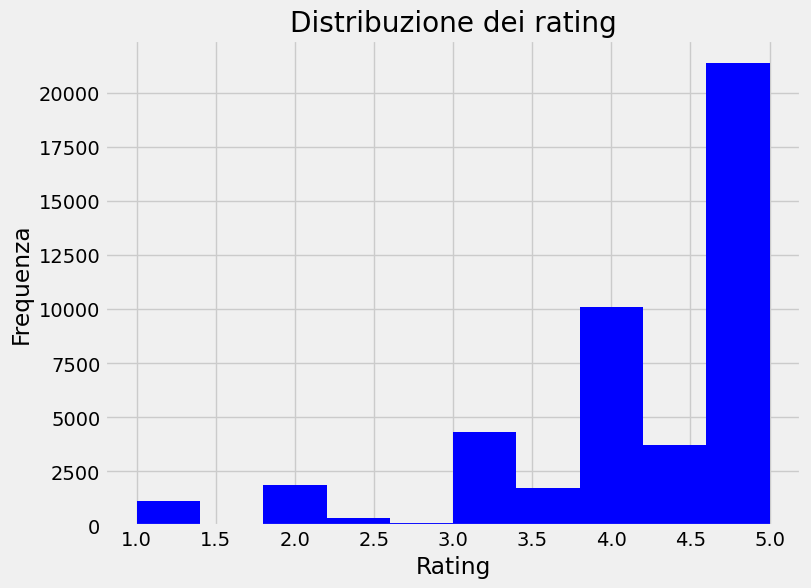

In [ ]:
# Creazione di un istogramma
plt.figure(figsize=(8, 6))
plt.hist(mean_rating_user_ID['rating'], bins=10, color='blue')

plt.title('Distribuzione dei rating')
plt.xlabel('Rating')
plt.ylabel('Frequenza')

plt.show()


In [ ]:
#CERCO I RATING DI OGNI ITEM_ID
mean_rating_item_ID = df.groupby('item_id')[['rating']].mean().sort_values(by= 'item_id', ascending= True)
print(mean_rating_item_ID)

           rating
item_id          
6454     3.818182
7443     3.772502
11960    4.033958
16411    3.668254
21296    4.171760
...           ...
155308   4.700000
155317   4.575758
155537   4.090909
155597   3.285714
155950   4.000000

[1020 rows x 1 columns]


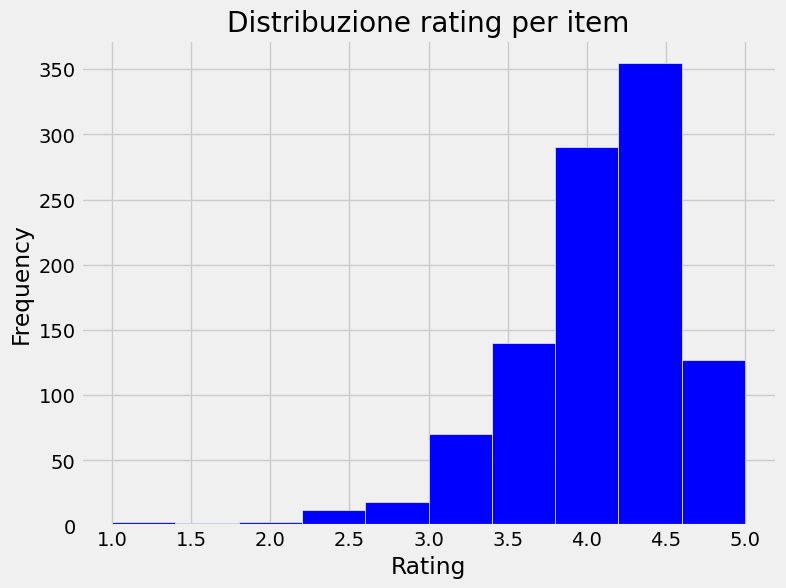

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.rcParams['patch.force_edgecolor'] = True

# Creazione dell'istogramma con matplotlib
plt.hist(mean_rating_item_ID['rating'], bins=10, color='blue')

plt.title('Distribuzione rating per item')
plt.xlabel('Rating')
plt.ylabel('Frequency')

plt.show()

In [ ]:
# LOWEST RATED CATEGORY
lowest_rated = mean_rating['rating'].idxmin()
print(lowest_rated)
df.loc[df['category'] == lowest_rated]

lowest_rated_ID = mean_rating_user_ID['rating'].idxmin()
print(lowest_rated_ID)
df.loc[df['category'] == lowest_rated]

Bottoms
ztubbenhauer


,item_id,user_id,rating,category
280,21296,Petra,5,Bottoms
281,21296,ejs,4,Bottoms
292,21296,Brandi,5,Bottoms
318,21296,Momo,5,Bottoms
323,21296,Jackie,5,Bottoms
...,...,...,...,...
99872,108981,carey,3,Bottoms
99875,73186,tessa,4,Bottoms
99877,77949,jaime,5,Bottoms
99885,77949,rachel,5,Bottoms


ANALIZZO LA DISTRIBUZIONE DEI RATING DEL DATA SET (df)

In [ ]:
df.groupby('rating')['rating'].count()

#LE CATEGORIE DI CUI SOPRA HANNO UN SET DI DATI MOLTO BASSO.
#USO LA MEDIA BAYESIANA
categories_stats = df.groupby('category')[['rating']].agg(['count', 'mean'])
print(categories_stats)
categories_stats.columns = categories_stats .columns.droplevel()
print(categories_stats.columns)

          rating          
           count      mean
category                  
Bottoms    23624  4.185278
Dresses    34160  4.230562
Outerwear   7131  4.217361
Tops       34977  4.203991
Index(['count', 'mean'], dtype='object')


MEDIA RATING DI OGNI USER PER CATEGORIA

In [ ]:
df.groupby('user_id')['rating'].mean().sort_values(ascending=False).head()
df.groupby('category')['rating'].mean().sort_values(ascending=False).head()


category
Dresses      4.230562
Outerwear    4.217361
Tops         4.203991
Bottoms      4.185278
Name: rating, dtype: float64

CONTROLLO SE CI SONO USER CHE HANNO VOTATO PIU VOLTE LO STESSO ELEMENTO

In [ ]:
fd = df[df.rating > 1].sort_values(by = 'rating' , ascending=False)
fd.head()

,item_id,user_id,rating,category
82343,153467,sherry,5,Tops
41313,77949,Valerie,5,Bottoms
41284,27439,Natalie,5,Outerwear
41285,115417,chelseaevusher,5,Bottoms
77317,153643,B,5,Dresses


In [ ]:
fd.tail()

,item_id,user_id,rating,category
34511,16411,kelseygordon13,2,Dresses
72973,121554,dangermouserocks,2,Bottoms
72974,44261,dangermouserocks,2,Tops
72976,84436,eillamarie,2,Tops
51427,82288,shakenbaker7,2,Dresses


In [ ]:
users_ids = df['user_id'].unique()
items_ids = df['item_id'].unique()

RIDUCO IL DATASET

In [ ]:
most_rated_items = fd.item_id.value_counts().head(300).index
most_rating_users = fd.user_id.value_counts().head(20000).index

fd_mid = fd[df.item_id.isin(most_rated_items)]
fd_mid = fd_mid[fd_mid.user_id.isin(most_rating_users)]

In [ ]:
fd_mid.size

255348

In [ ]:
print(fd.shape)
print(fd_mid.shape)

(96369, 4)
(63837, 4)


In [ ]:
fd_mid = fd_mid[fd_mid.user_id.isin(most_rating_users)]
fd_mid = fd_mid[fd_mid.item_id.isin(most_rated_items)]

In [ ]:
fd_mid.head()

,item_id,user_id,rating,category
41313,77949,Valerie,5,Bottoms
41284,27439,Natalie,5,Outerwear
41285,115417,chelseaevusher,5,Bottoms
77317,153643,B,5,Dresses
41287,67507,katieraealbin,5,Tops


#  2. KNN: Configurazione ottimale dell’algoritmo K-NN per la predizione dei rating

CREO UN OGGETTO PER CONVERTIRE IL DATASET (fd) IN UN FORMATO UTILIZZABILE DA SURPRISE

In [ ]:
reader = Reader(rating_scale=(1, 5))

# **Grid Search:**
La Grid Search è una tecnica di ricerca dei parametri ottimali per un modello di apprendimento automatico. Questa tecnica coinvolge l'esplorazione di una griglia di combinazioni di valori dei parametri specificati in anticipo per determinare la combinazione che produce le migliori prestazioni del modello.

Determiniamo la miglior combinazione degli iperparamentri

In [ ]:
ds_gridset = Dataset.load_from_df(fd_mid.sample(frac=0.2)[['user_id', 'item_id', 'rating']], reader)

param_grid = {
    'k': [5, 10, 15, 20, 25],
    'sim_options': {'name': ['cosine', 'pearson'],'user_based': [True, False]} }

gs = GridSearchCV(KNNBasic, param_grid, measures=['rmse', 'mse'])
gs.fit(ds_gridset)

Computing the cosine similarity matrix...
Done computing similarity matrix.
Computing the cosine similarity matrix...
Done computing similarity matrix.
Computing the cosine similarity matrix...
Done computing similarity matrix.
Computing the cosine similarity matrix...
Done computing similarity matrix.
Computing the cosine similarity matrix...
Done computing similarity matrix.
Computing the cosine similarity matrix...
Done computing similarity matrix.
Computing the cosine similarity matrix...
Done computing similarity matrix.
Computing the cosine similarity matrix...
Done computing similarity matrix.
Computing the cosine similarity matrix...
Done computing similarity matrix.
Computing the cosine similarity matrix...
Done computing similarity matrix.
Computing the pearson similarity matrix...
Done computing similarity matrix.
Computing the pearson similarity matrix...
Done computing similarity matrix.
Computing the pearson similarity matrix...
Done computing similarity matrix.
Computing

Risultati:

In [ ]:
print(f'Best RMSE = {gs.best_score["rmse"]:.4f}')
print(f'Best MSE = {gs.best_score["mse"]:.4f}')
print(f'Best configuration = {gs.best_params["rmse"]}')

Best RMSE = 0.9456
Best MSE = 0.8945
Best configuration = {'k': 5, 'sim_options': {'name': 'pearson', 'user_based': True}}


DETERMINO L'ERRORE MEDIO CON IL CROSS VALIDATION

In [ ]:
# CONVERTO IL DATAFRAME IN UN FORMATO PER SURPRISE
ds_cv = Dataset.load_from_df(fd_mid.sample(frac=0.2)[['user_id', 'item_id', 'rating']], reader)

algo = KNNBasic( k=gs.best_params['rmse']['k'], sim_options= {'name': 'pearson', 'user_based': True} )
kfold_result = cross_validate(algo, ds_cv, measures=['RMSE', 'MSE'], cv=5, verbose=True)


Computing the pearson similarity matrix...
Done computing similarity matrix.
Computing the pearson similarity matrix...
Done computing similarity matrix.
Computing the pearson similarity matrix...
Done computing similarity matrix.
Computing the pearson similarity matrix...
Done computing similarity matrix.
Computing the pearson similarity matrix...
Done computing similarity matrix.
Evaluating RMSE, MSE of algorithm KNNBasic on 5 split(s).

                  Fold 1  Fold 2  Fold 3  Fold 4  Fold 5  Mean    Std     
RMSE (testset)    0.9576  0.9548  0.9509  0.9323  0.9491  0.9489  0.0088  
MSE (testset)     0.9171  0.9116  0.9042  0.8692  0.9008  0.9006  0.0167  
Fit time          2.41    2.64    2.52    2.67    2.79    2.61    0.13    
Test time         0.08    0.08    0.08    0.13    0.08    0.09    0.02    


Fitto il modello su tutto il dataset

In [ ]:
ds = Dataset.load_from_df(fd_mid[['user_id', 'item_id', 'rating']], reader)

In [ ]:
# Costruisco il training set
trainset = ds.build_full_trainset()

In [ ]:
algo = KNNBasic()

In [ ]:
algo.fit(trainset)

Computing the msd similarity matrix...
Done computing similarity matrix.


In [ ]:
import random

for _ in range(10):
    sample_row = fd_mid.sample().iloc[0]
    user_id = sample_row['user_id']
    item_id = sample_row['item_id']

    prediction = algo.predict(user_id, item_id, r_ui=2, verbose=True)
    estimated_rating = prediction.est

    print(f"User: {user_id}\tItem: {item_id}\tEstimated Rating: {estimated_rating}")

user: josephine.grahm item: 65046      r_ui = 2.00   est = 5.00   {'actual_k': 40, 'was_impossible': False}
User: josephine.grahm	Item: 65046	Estimated Rating: 5
user: sarah.j.hashmi item: 54887      r_ui = 2.00   est = 4.00   {'actual_k': 40, 'was_impossible': False}
User: sarah.j.hashmi	Item: 54887	Estimated Rating: 4.0
user: karen.w.linder item: 48629      r_ui = 2.00   est = 4.00   {'actual_k': 40, 'was_impossible': False}
User: karen.w.linder	Item: 48629	Estimated Rating: 4.0
user: nicole     item: 142983     r_ui = 2.00   est = 4.86   {'actual_k': 40, 'was_impossible': False}
User: nicole	Item: 142983	Estimated Rating: 4.864261450026822
user: anderson.kelly item: 34935      r_ui = 2.00   est = 5.00   {'actual_k': 40, 'was_impossible': False}
User: anderson.kelly	Item: 34935	Estimated Rating: 5
user: cpresti    item: 68332      r_ui = 2.00   est = 4.00   {'actual_k': 40, 'was_impossible': False}
User: cpresti	Item: 68332	Estimated Rating: 4.0
user: christinia item: 31752      r_ui

# 3. MATRICE DEI RATIG

Predizione dei valori della matrice di rating e costruzione di un'altra matrice per tenere traccia dei valori che sono stati predetti

In [ ]:
users_subset = users_ids[:1500]

rating_matrix = np.zeros((len(users_subset), len(items_ids)))
is_predicted = np.zeros((len(users_subset), len(items_ids)))

fd_mid.set_index(['user_id', 'item_id'], inplace=True)

In [ ]:
for i, user in enumerate(users_subset):
    for j, item in enumerate(items_ids):

        if (user, item) in fd_mid.index:
            rating_matrix[i, j] = fd_mid.loc[user, item]['rating']

        else:
            rating_matrix[i, j] = round(algo.predict(user, item).est)
            is_predicted[i, j] = 1

fd_mid.reset_index(inplace=True)

Controllo se sono stati generati valori predetti

In [ ]:
is_predicted[:10, :10]

array([[0., 1., 1., 0., 1., 1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
       [0., 1., 1., 0., 0., 1., 1., 1., 0., 0.],
       [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
       [0., 1., 0., 1., 1., 1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
       [0., 1., 0., 0., 1., 1., 1., 0., 1., 1.],
       [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
       [0., 1., 0., 0., 1., 1., 1., 1., 0., 1.],
       [0., 1., 1., 1., 1., 1., 1., 1., 1., 1.]])

In [ ]:
rating_matrix[:10, :10]

array([[4., 4., 5., 5., 5., 5., 4., 5., 5., 5.],
       [4., 4., 4., 4., 4., 4., 4., 4., 4., 4.],
       [4., 5., 5., 5., 4., 5., 4., 5., 5., 5.],
       [4., 4., 4., 4., 4., 4., 4., 4., 4., 4.],
       [4., 4., 3., 5., 4., 4., 4., 5., 4., 5.],
       [4., 4., 4., 4., 4., 4., 4., 4., 4., 4.],
       [2., 5., 5., 5., 5., 5., 5., 5., 5., 5.],
       [4., 4., 4., 4., 4., 4., 4., 4., 4., 4.],
       [4., 5., 3., 5., 4., 5., 4., 5., 3., 5.],
       [4., 5., 5., 5., 5., 5., 4., 5., 4., 5.]])

# 4. SEGMENTAZIONE DEGLI UTENTI IN BASE ALLE PREFERENZE:
Algoritmo di clustering K-MEANS con cosine similarity.
L'obiettivo dell'analisi dei cluster è quello di raggruppare gli oggetti in modo che gli oggetti all'interno di uno stesso cluster siano simili tra loro e gli oggetti tra i diversi cluster siano diversi.

Definisco la matrice di rating con valori mancanti impostati a 0.
Quest matrice rappresenta i rating degli utenti per ogni elemento. I valori mancanti indicano che non è disponibile una valutazione per quella combinazione in particolare.

In [ ]:
matrice_kmeans_mid = np.zeros((len(most_rating_users), len(most_rated_items)))

fd_mid.set_index(['user_id', 'item_id'], inplace=True)

In [ ]:
for i, user_id in enumerate(most_rating_users):
    for j, item_id in enumerate(most_rated_items):

        if (user_id, item_id) in fd_mid.index:
            matrice_kmeans_mid[i, j] = fd_mid.loc[user_id, item_id]['rating']

        else:
            matrice_kmeans_mid[i, j] = 0

fd_mid.reset_index(inplace=True)

In [ ]:
# rimuovo le righe con tutti gli 0
matrice_kmeans_mid = matrice_kmeans_mid[~np.all(matrice_kmeans_mid == 0, axis=1)]
print(matrice_kmeans_mid.shape)

(18990, 300)


In [ ]:
matrice_kmeans_mid[:10, :10]

array([[2., 0., 5., 5., 5., 5., 4., 5., 5., 2.],
       [4., 5., 4., 5., 4., 3., 5., 5., 5., 4.],
       [5., 4., 4., 5., 4., 2., 0., 5., 4., 4.],
       [5., 2., 5., 4., 5., 5., 0., 3., 4., 0.],
       [5., 5., 4., 5., 4., 5., 2., 5., 4., 5.],
       [4., 5., 3., 4., 2., 5., 5., 2., 0., 4.],
       [3., 5., 5., 4., 5., 3., 3., 5., 5., 5.],
       [5., 4., 3., 5., 5., 3., 3., 4., 4., 0.],
       [5., 5., 5., 5., 5., 5., 0., 5., 5., 4.],
       [5., 2., 5., 4., 3., 4., 5., 5., 3., 4.]])

#DETERMINO IL NUMERO k DI CLUSTER IDEALE CON IL METODO ELBOW

Definisco una funzione per il calcolo del WCSS.
WCSS (Within-Cluster Sum of Squares) è una misura utilizzata nell'analisi dei cluster per valutare la coesione dei dati all'interno di ciascun cluster.

Il WCSS misura la somma delle distanze quadrate tra ogni oggetto e il centroide del cluster a cui appartiene.

Più piccolo è il valore del WCSS, più i punti all'interno di ciascun cluster sono vicini tra loro, indicando una maggiore coesione. Al contrario, se il valore del WCSS è grande, significa che i punti all'interno dei cluster sono più dispersi e meno coerenti.

Nell'analisi dei cluster, si cerca di minimizzare il valore del WCSS cercando configurazioni di cluster ottimali.

In sintesi, il WCSS è una misura che quantifica quanto i punti all'interno di un cluster siano vicini tra loro, fornendo un modo per valutare la qualità di un'analisi dei cluster.

In [ ]:
def get_wcss(rating_matrix_kmeans, clusters, centroids):
    wcss = 0
    for i in range(len(clusters)):
        wcss += cosine_distance(rating_matrix_kmeans[i], centroids[clusters[i]])
    return wcss

La funzione get_wcss calcola la somma delle distanze di coseno tra i punti e i centroidi dei rispettivi cluster, fornendo una misura della dispersione dei punti all'interno dei cluster.

In [ ]:
from nltk.cluster import KMeansClusterer, cosine_distance

from surprise import Dataset, Reader
from surprise.model_selection import cross_validate
from surprise import KNNBasic
from surprise import SVD
from surprise.model_selection import GridSearchCV, cross_validate


DEFINIAMO L'IPERPARAMETRO k CON IL METODO ELBOW

Il metodo del "gomito" (elbow method) è una tecnica comune utilizzata per determinare il numero ottimale di cluster da utilizzare nell'algoritmo K-means. Questo metodo si basa sull'idea che, aumentando il numero di cluster, la varianza intra-cluster diminuirà, ma ad un certo punto diminuirà in modo meno significativo. L'idea è quindi di cercare il punto in cui il miglioramento nella varianza intra-cluster inizia a diminuire drasticamente, creando un "gomito" nel grafico.

In [ ]:
wcss = []

for i in range(1, 30):
    kclusterer = KMeansClusterer(i, distance=cosine_distance, avoid_empty_clusters=True)
    clusters = kclusterer.cluster(matrice_kmeans_mid, assign_clusters=True)
    wcss.append(get_wcss(matrice_kmeans_mid, clusters, kclusterer.means()))
    print('Numero di cluster:', i, 'WCSS:', wcss[-1])

Numero di cluster: 1 WCSS: 16447.227306305485
Numero di cluster: 2 WCSS: 16007.566951729403
Numero di cluster: 3 WCSS: 15570.001250891048
Numero di cluster: 4 WCSS: 15328.34305440445
Numero di cluster: 5 WCSS: 15402.956720090444
Numero di cluster: 6 WCSS: 15154.858991939664
Numero di cluster: 7 WCSS: 14589.28404228312
Numero di cluster: 8 WCSS: 14613.019703603546
Numero di cluster: 9 WCSS: 14559.926065190597
Numero di cluster: 10 WCSS: 14185.608316189262
Numero di cluster: 11 WCSS: 13862.108279010046
Numero di cluster: 12 WCSS: 13798.213938326691
Numero di cluster: 13 WCSS: 13433.16177613757
Numero di cluster: 14 WCSS: 13371.52342296375
Numero di cluster: 15 WCSS: 13301.205053558846
Numero di cluster: 16 WCSS: 12728.384885808975
Numero di cluster: 17 WCSS: 12792.14145839495
Numero di cluster: 18 WCSS: 13059.678923256972
Numero di cluster: 19 WCSS: 12375.309292656733
Numero di cluster: 20 WCSS: 12433.155446987563
Numero di cluster: 21 WCSS: 12253.269590076516
Numero di cluster: 22 WCSS:

In [ ]:
wcss

[16447.227306305485,
 16007.566951729403,
 15570.001250891048,
 15328.34305440445,
 15402.956720090444,
 15154.858991939664,
 14589.28404228312,
 14613.019703603546,
 14559.926065190597,
 14185.608316189262,
 13862.108279010046,
 13798.213938326691,
 13433.16177613757,
 13371.52342296375,
 13301.205053558846,
 12728.384885808975,
 12792.14145839495,
 13059.678923256972,
 12375.309292656733,
 12433.155446987563,
 12253.269590076516,
 12368.181945677206,
 11814.706493914826,
 11996.630538803696,
 11658.004420650823,
 11439.43837289821,
 11945.09599402431,
 11794.47577406181,
 11274.368466210462]

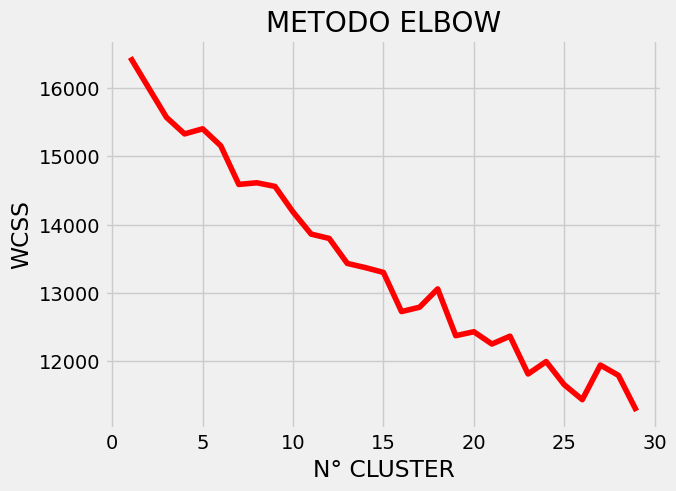

In [ ]:
plt.plot(range(1, 30), wcss, color='red')
plt.title('METODO ELBOW')
plt.xlabel('N° CLUSTER')
plt.ylabel('WCSS')
plt.show()

Definiamo l'iperparametro k con il metodo elbow (rating anche predetti)

In [ ]:
wcss = []

for i in range(1, 30):
    kclusterer = KMeansClusterer(i, distance=cosine_distance, avoid_empty_clusters=True)
    clusters = kclusterer.cluster(rating_matrix, assign_clusters=True)
    wcss.append(get_wcss(rating_matrix, clusters, kclusterer.means()))
    print('Numero di cluster:', i, 'WCSS:', wcss[-1])

Numero di cluster: 1 WCSS: 1.9205815986017547
Numero di cluster: 2 WCSS: 1.1892695932980635
Numero di cluster: 3 WCSS: 1.1398192189052019
Numero di cluster: 4 WCSS: 1.107160597357742
Numero di cluster: 5 WCSS: 1.1256582405108138
Numero di cluster: 6 WCSS: 1.0926155433892706
Numero di cluster: 7 WCSS: 1.0893671581201236
Numero di cluster: 8 WCSS: 1.0845787136462233
Numero di cluster: 9 WCSS: 1.1139155305222752
Numero di cluster: 10 WCSS: 1.108558158039685
Numero di cluster: 11 WCSS: 1.0220593870388714
Numero di cluster: 12 WCSS: 1.0758785308460777
Numero di cluster: 13 WCSS: 1.1013539963568946
Numero di cluster: 14 WCSS: 1.035435183968554
Numero di cluster: 15 WCSS: 1.0403329425543306
Numero di cluster: 16 WCSS: 1.0430888373195348
Numero di cluster: 17 WCSS: 1.047120785338859
Numero di cluster: 18 WCSS: 1.0382496779671924
Numero di cluster: 19 WCSS: 1.0336078735183798
Numero di cluster: 20 WCSS: 1.0125886878338592
Numero di cluster: 21 WCSS: 1.0076188783140012
Numero di cluster: 22 WCSS

In [ ]:
wcss

[1.9205815986017547,
 1.1892695932980635,
 1.1398192189052019,
 1.107160597357742,
 1.1256582405108138,
 1.0926155433892706,
 1.0893671581201236,
 1.0845787136462233,
 1.1139155305222752,
 1.108558158039685,
 1.0220593870388714,
 1.0758785308460777,
 1.1013539963568946,
 1.035435183968554,
 1.0403329425543306,
 1.0430888373195348,
 1.047120785338859,
 1.0382496779671924,
 1.0336078735183798,
 1.0125886878338592,
 1.0076188783140012,
 1.0581097016164298,
 1.0190076882893662,
 1.0069664304971406,
 1.001800635926193,
 1.0049854127317808,
 0.9814744734665405,
 0.9870222616671039,
 0.9850086232313651]

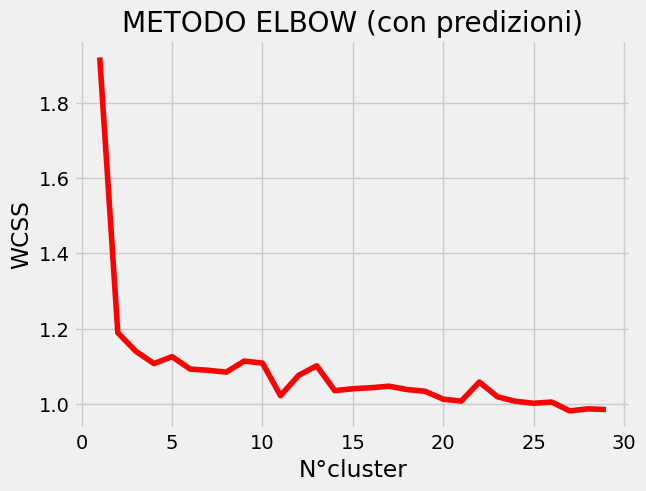

In [ ]:
plt.plot(range(1, 30), wcss, color='red')
plt.title('METODO ELBOW (con predizioni)')
plt.xlabel('N°cluster')
plt.ylabel('WCSS')
plt.show()

# Eseguo il k-MEANS

Considero k = 2 (cluster)
CLUSTER_0; CLUSTER_1

In [ ]:
n_clusters = 2

kmeans_clusterer = KMeansClusterer(n_clusters, distance=cosine_distance, avoid_empty_clusters=True)

clusters = kmeans_clusterer.cluster(rating_matrix, assign_clusters=True)
users_clusters = dict(zip(users_ids, clusters))

Utenti associati al corrispettivo cluster

In [ ]:
users_clusters

{'Alex': 1,
 'carolyn.agan': 0,
 'Robyn': 1,
 'De': 0,
 'tasha': 1,
 'gina.chihos': 0,
 'Kim': 1,
 'jess.betcher': 0,
 'Elissa': 1,
 'Yvette': 1,
 'Allyson': 1,
 'bcornwell': 1,
 'emily.opala': 0,
 'krista': 1,
 'radhika.mulani': 1,
 'Lina': 1,
 'Karolynne': 0,
 'Laurelle': 0,
 'mjcuyler': 0,
 'vickic88': 0,
 'Monica': 1,
 's_curtis82': 0,
 'Tia': 1,
 'Mindy': 1,
 'krystalmarie': 0,
 'tiffanyl85': 1,
 'Talia': 1,
 'chelsmitch': 1,
 'Nichole': 1,
 'Jacqueline': 1,
 'Danica': 1,
 'poisonlake': 0,
 'Emmy': 1,
 'Victoria': 1,
 'Jacque': 0,
 'Bethany': 1,
 'Kelsey': 1,
 'emilie.mercier': 0,
 'Kirstin': 1,
 'natashia': 1,
 'Loni': 0,
 'Shanna': 1,
 'Cassandra': 1,
 'MaryJackelyn': 0,
 'civilwarchick': 1,
 'Julianna': 1,
 'chandlen91': 0,
 'Laksmi': 0,
 'Nina': 1,
 'lenderle': 0,
 'Candice': 1,
 'lolaagain': 0,
 'flanniedc': 0,
 'Paige': 1,
 'Haley': 1,
 'lubdubart': 0,
 'Shawna': 1,
 'Tahlia': 1,
 'Alice': 1,
 'Mazette': 0,
 'Rose': 1,
 'Pauline': 1,
 'lpstewart': 0,
 'natalia': 1,
 'A.': 1,

Analisi della distribuzione degli utenti nei cluster

In [ ]:
user_per_cluster = []

for i in range(n_clusters):
    user_per_cluster.append(len([x for x in users_clusters.values() if x == i]))
    print('Cluster', i, 'utenti:', user_per_cluster[i])

Cluster 0 utenti: 596
Cluster 1 utenti: 904


In [ ]:
cluster_0 = []
cluster_1 = []

for i in(users_clusters):
    cluster = users_clusters[i]
    if cluster == 0:
        cluster_0.append(i)
    if cluster == 1:
        cluster_1.append(i)

UTENTI CLUSTER_0

In [ ]:
# Creazione della lista di utenti nel cluster_0
cluster_0_users = [user for user, cluster in users_clusters.items() if cluster == 0]

# Creazione della tabella con i risultati del cluster_0
cluster_0_table = pd.DataFrame({'User ID': cluster_0_users})

cluster_0_table.head(11)

,User ID
0,carolyn.agan
1,De
2,gina.chihos
3,jess.betcher
4,emily.opala
5,Karolynne
6,Laurelle
7,mjcuyler
8,vickic88
9,s_curtis82


UTENTI CLUSTER_1

In [ ]:
# Creazione della lista di utenti nel cluster 1
cluster_1_users = [user for user, cluster in users_clusters.items() if cluster == 1]

# Creazione della tabella con i risultati del cluster 0
cluster_1_table = pd.DataFrame({'User ID': cluster_1_users})

cluster_1_table.head(11)

,User ID
0,Alex
1,Robyn
2,tasha
3,Kim
4,Elissa
5,Yvette
6,Allyson
7,bcornwell
8,krista
9,radhika.mulani


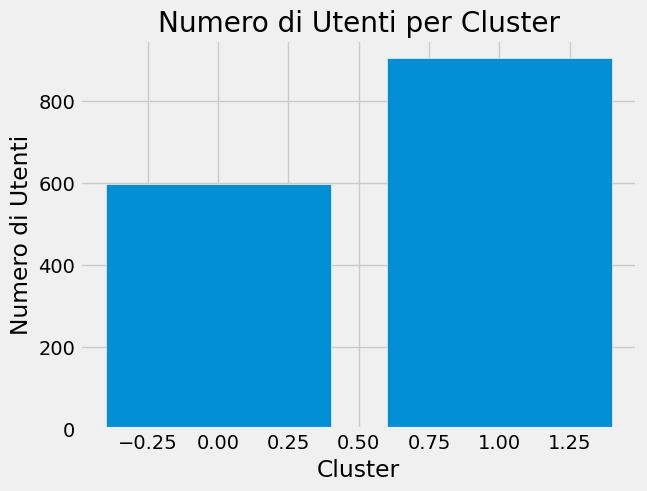

In [ ]:
# Creazione del DataFrame
df_user_per_cluster = pd.DataFrame({'Cluster': range(n_clusters), 'Utenti': user_per_cluster})

# Creazione del grafico a barre
plt.bar(df_user_per_cluster['Cluster'], df_user_per_cluster['Utenti'])
plt.xlabel('Cluster')
plt.ylabel('Numero di Utenti')
plt.title('Numero di Utenti per Cluster')
plt.show()

# **5.  CREO PER OGNI UTENTE UNA LISTA DEGLI "n" OGGETTI DA CONSIGLIARE**

In [ ]:
def get_top_n_item(user, item, rating_matrix, is_predicted, n=10):

    items_suggeriti = {}

    for i, user_id in enumerate(user):

        sorting_rating_index = np.argsort(rating_matrix[i])[::-1]
        sorting_rating_index = sorting_rating_index[is_predicted[i][sorting_rating_index] == 1]

        items_suggeriti [user_id] = item[sorting_rating_index][:n]


    items_suggeriti  = pd.DataFrame.from_dict(items_suggeriti , orient='index')
    items_suggeriti .columns = ['ITEM_' + str(i) for i in range(1, n+1)]
    items_suggeriti .index.name = 'USER_ID'

    return items_suggeriti

In [ ]:
get_top_n_item(users_subset, items_ids, rating_matrix, is_predicted, n=10).head(5)

,ITEM_1,ITEM_2,ITEM_3,ITEM_4,ITEM_5,ITEM_6,ITEM_7,ITEM_8,ITEM_9,ITEM_10
USER_ID,,,,,,,,,,
Alex,102736,142983,82288,153081,123500,85507,132261,143686,153709,84436
carolyn.agan,153228,106348,135264,151263,150583,150788,150982,137816,150984,150712
Robyn,82288,141880,153081,145278,108981,141845,110169,143136,113512,104356
De,153228,106348,135264,151263,150583,150788,150982,137816,150984,150712
tasha,116313,110169,107794,141072,126821,153454,108981,153881,113643,106242


In [ ]:
grouped_df = fd_mid.groupby(['item_id', 'category']).size().reset_index(name='count')

In [ ]:
grouped_df

,item_id,category,count
0,6454,Dresses,49
1,7443,Dresses,666
2,11960,Outerwear,607
3,16411,Dresses,766
4,21296,Bottoms,1152
...,...,...,...
295,153962,Dresses,41
296,154064,Dresses,61
297,154329,Tops,45
298,154797,Dresses,37


In [ ]:
item_id = 132261 # Item_id da cercare

category = dfc.reset_index().loc[dfc['item_id'] == item_id, 'category'].values[0]
print(category)

Tops


# *6.  FILLING DELLA MATRICE DI RATING*
MATRIX FACTORIZATION (MF)
L'idea principale di MF è rappresentare gli utenti e gli elementi in uno spazio di fattori a dimensione ridotta, in cui ogni utente e elemento è descritto da un vettore di fattori. Moltiplicando questi vettori di fattori, si ottiene una stima approssimata della matrice di rating completa.

Utilizzo di nuovo la grid search per individuare i parametri migliori

In [ ]:
ds_gs_mf = Dataset.load_from_df(fd_mid.sample(frac=0.2)[['user_id', 'item_id', 'rating']], reader)

param_grid_mf = {
    'lr_all': [0.001, 0.002, 0.003, 0.004, 0.005],
    'reg_all': [0.04, 0.05, 0.06],
    'n_epochs': [5, 10, 20],
    'n_factors': [25, 50, 100]
}

gs_mf = GridSearchCV(SVD, param_grid_mf, measures=['rmse', 'mse'])
gs_mf.fit(ds_gs_mf)

In [ ]:
print(f'Best RMSE = {gs_mf.best_score["rmse"]:.4f}')

print(f'Best MSE = {gs_mf.best_score["mse"]:.4f}')

print(f'Best configuration = {gs_mf.best_params["rmse"]}')

Best RMSE = 0.8945
Best MSE = 0.8002
Best configuration = {'lr_all': 0.005, 'reg_all': 0.06, 'n_epochs': 10, 'n_factors': 25}


Utilizziamo i migliori parametri per matrix factorization sul dataset e determiniamo l'errore medio

In [ ]:
ds_cv_mf = Dataset.load_from_df(fd_mid.sample(frac=0.2)[['user_id', 'item_id', 'rating']], reader)

algo_mf = SVD(
    lr_all = gs_mf.best_params['rmse']['lr_all'],
    reg_all = gs_mf.best_params['rmse']['reg_all'],
    n_epochs = gs_mf.best_params['rmse']['n_epochs'],
    n_factors = gs_mf.best_params['rmse']['n_factors'] )

result_mf = cross_validate(algo_mf, ds_cv_mf, measures=['RMSE', 'MSE'], cv=5, verbose=True)

Evaluating RMSE, MSE of algorithm SVD on 5 split(s).

                  Fold 1  Fold 2  Fold 3  Fold 4  Fold 5  Mean    Std     
RMSE (testset)    0.9296  0.8985  0.9085  0.9009  0.9171  0.9109  0.0114  
MSE (testset)     0.8642  0.8073  0.8255  0.8116  0.8411  0.8299  0.0208  
Fit time          0.04    0.05    0.05    0.06    0.07    0.05    0.01    
Test time         0.02    0.04    0.01    0.01    0.02    0.02    0.01    


Fitting del modello su tutto il dataset

In [ ]:
ds_mf = Dataset.load_from_df(fd_mid[['user_id', 'item_id', 'rating']], reader)

In [ ]:
trainset_mf = ds_mf.build_full_trainset()

In [ ]:
algo_mf.fit(trainset_mf)

RIEMPIMENTO DELLA MATRICE DI RATING (Matrix Factorization)

In [ ]:
user_subset_mf = users_ids[:1000]

rating_matrix_mf = np.zeros((len(user_subset_mf), len(items_ids)))
is_predicted_mf = np.zeros((len(user_subset_mf), len(items_ids)))

fd.set_index(['user_id', 'item_id'], inplace=True)

In [ ]:
for i, user in enumerate(user_subset_mf):
    for j, item in enumerate(items_ids):

        if (user, item) in fd.index:
            rating_matrix_mf[i, j] = fd.loc[user, item]['rating']

        else:
            rating_matrix_mf[i, j] = round(algo_mf.predict(user, item).est)
            is_predicted_mf[i, j] = 1

fd.reset_index(inplace=True)

In [ ]:
is_predicted_mf[:10, :10]

array([[0., 1., 1., 0., 1., 1., 1., 1., 1., 1.],
       [0., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
       [0., 1., 1., 0., 0., 1., 1., 1., 0., 0.],
       [0., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
       [0., 1., 0., 1., 1., 1., 1., 1., 1., 1.],
       [0., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
       [0., 1., 0., 0., 1., 1., 1., 0., 1., 1.],
       [0., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
       [0., 1., 0., 0., 1., 1., 1., 1., 0., 1.],
       [0., 1., 1., 1., 1., 1., 1., 1., 1., 1.]])

In [ ]:
rating_matrix_mf[:10, :10]

array([[4., 4., 4., 5., 4., 4., 4., 4., 4., 4.],
       [3., 4., 4., 4., 4., 4., 4., 4., 4., 4.],
       [4., 4., 4., 5., 4., 4., 4., 4., 5., 5.],
       [4., 4., 4., 4., 4., 4., 4., 4., 4., 4.],
       [4., 4., 3., 4., 4., 4., 4., 4., 4., 4.],
       [5., 4., 4., 4., 4., 4., 4., 4., 4., 4.],
       [2., 4., 5., 5., 4., 4., 4., 5., 4., 4.],
       [5., 4., 4., 4., 4., 4., 4., 4., 4., 4.],
       [4., 4., 3., 5., 4., 4., 4., 4., 3., 4.],
       [4., 4., 4., 4., 4., 4., 4., 4., 4., 4.]])

# **FINE**